# FFOR grid 20_0

Notebook per calcolare una prima FFOR della rete `20_0` il 15 settembre alle 15:00, usando `grid_loader_mveq` come punto di partenza e Gurobi come solver LP.

Scelte operative lasciate come parametri in alto:
- i percorsi di input restano quelli del loader e dei file `20_0`;
- 8 direzioni dell'obiettivo: `0, 45, ..., 315` gradi, con pesi non normalizzati, per esempio `45 deg -> alpha=1, beta=1`;
- la FFOR e riportata in `pu`, come deviazione rispetto alla baseline del PCC;
- convenzione paper/iniezione al PCC: consumo o import dalla HV negativo, generazione o export verso HV positivo;
- le colonne assolute usano quindi `P_pcc_injection_pu = -P_pcc_import_pu` e `Q_pcc_injection_pu = -Q_pcc_import_pu`;
- `P_flex_pu = P_pcc_injection_pu - P_base_injection_pu`, quindi `P_flex_pu > 0` significa aumento generazione o diminuzione consumo;
- `SOC_AT_T = 0.5` e usato solo come stato iniziale assunto nel timestep corrente;
- il timestep successivo delle BESS e limitato a `SOC_MIN = 0.40` e `SOC_MAX = 0.80`;
- le BESS sono modellate con una sola potenza attiva netta `bess_p`: `bess_p > 0` scarica, `bess_p < 0` carica;
- il vincolo SOC BESS non considera efficienze di carica/scarica: `SOC_next = SOC_AT_T - bess_p * DT_H / capacity_kWh`;
- banda termica HP `19-21 C`, perche le foto danno la dinamica ma non i limiti di comfort.


In [ ]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB
from types import SimpleNamespace

from grid_loader_mveq import Grid20Loader

GRID_NAME = "20_0"
DATA_YEAR = 2030
TARGET_TIME = "12-15 20:00:00"
NEXT_TIME = "12-15 21:00:00"

SBASE_MVA = 100.0
SBASE_KW = SBASE_MVA * 1000.0
SBASE_KVAR = SBASE_MVA * 1000.0

PF_DER = 0.95
TAN_PHI = math.tan(math.acos(PF_DER))
DT_H = 0.25

SOC_AT_T = 0.60
SOC_MIN = 0.40
SOC_MAX = 0.80
T_SET_C = 20.0
T_MIN_C = 19.0
T_MAX_C = 21.0

N_POLY = 8
INNER_POLY_RADIUS = math.cos(math.pi / N_POLY)
DIRECTION_WEIGHTS = {
    0: (1.0, 0.0),
    45: (1.0, 1.0),
    90: (0.0, 1.0),
    135: (-1.0, 1.0),
    180: (-1.0, 0.0),
    225: (-1.0, -1.0),
    270: (0.0, -1.0),
    315: (1.0, -1.0),
}
DIRECTIONS_DEG = list(DIRECTION_WEIGHTS.keys())

OUTPUT_DIR = Path("outputs") / f"ffor_{GRID_NAME}_{DATA_YEAR}_{TARGET_TIME.replace(' ', '_').replace(':', '-')}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)


## 1. Baseline PCC

Il loader mantiene la convenzione dei profili: `P > 0` e consumo. Nel modello di rete sotto, invece, le variabili nodali dei DER sono in convenzione di iniezione: PV e BESS discharge positive, HP negative.

In [2]:
loader = Grid20Loader(
    grid_name=GRID_NAME,
    data_year=DATA_YEAR,
    start_date="01-01 00:00:00",
    end_date="12-31 23:00:00",
    setpoint_c=T_SET_C,
)
loader.build_all_profiles()

def total_profile_value(name, timestamp=TARGET_TIME):
    df = pd.read_csv(Path("outputs") / f"{GRID_NAME}_profiles_mveq_{DATA_YEAR}" / f"{name}.csv")
    return float(df.loc[df["Unnamed: 0"].eq(timestamp), "value_kW"].iloc[0])

baseline_demand_pcc_kW = total_profile_value("baseline_demand_total")
hp_baseline_pcc_kW = total_profile_value("hp_baseline_total")
pv_baseline_pcc_kW = total_profile_value("pv_generation_total")
net_baseline_pcc_profile_kW = total_profile_value("net_baseline_total")
net_baseline_pcc_injection_kW = -net_baseline_pcc_profile_kW

baseline_summary = pd.DataFrame([
    {"quantity": "conventional demand", "loader_value_kW": baseline_demand_pcc_kW, "injection_convention_kW": -baseline_demand_pcc_kW},
    {"quantity": "HP baseline demand", "loader_value_kW": hp_baseline_pcc_kW, "injection_convention_kW": -hp_baseline_pcc_kW},
    {"quantity": "PV baseline production", "loader_value_kW": pv_baseline_pcc_kW, "injection_convention_kW": pv_baseline_pcc_kW},
    {"quantity": "net PCC baseline", "loader_value_kW": net_baseline_pcc_profile_kW, "injection_convention_kW": net_baseline_pcc_injection_kW},
])
baseline_summary


,quantity,loader_value_kW,injection_convention_kW
0,conventional demand,2922.196213,-2922.196213
1,HP baseline demand,26.802010,-26.802010
2,PV baseline production,492.320641,492.320641
3,net PCC baseline,2456.677581,-2456.677581


In [3]:
node_ids = [str(x) for x in loader.nodes["osmid"].astype(str)]
bus_ids = [int(x) + 1 for x in node_ids]
bus_to_pos = {bus: i for i, bus in enumerate(bus_ids)}
osmid_to_bus = {osmid: int(osmid) + 1 for osmid in node_ids}
n_bus = len(node_ids)

slack_bus = int(pd.read_excel("06_Grids/20_0_matpower.xlsx", sheet_name="generator_data").iloc[0]["GEN_BUS"])
slack_idx = bus_to_pos[slack_bus]
slack_osmid = str(slack_bus - 1)

print(f"MV nodes: {n_bus}")
print(f"Slack/PCC bus: MATPOWER {slack_bus}, MV_osmid {slack_osmid}")


MV nodes: 51
Slack/PCC bus: MATPOWER 45, MV_osmid 44


## 2. Asset DER e domanda fissa

- Domanda convenzionale: fissa, da `baseline_demand_by_mv_node`.
- PV: `0 <= P <= P_base`, `|Q| <= P tan(acos(0.95))`.
- HP: variabile di iniezione negativa, `-P_peak/0.8 <= P <= 0`, `Q = P tan(acos(0.95))`, e vincolo termico sul passo successivo.
- BESS: `S_max = P_nom`, unica potenza netta `P_bess`; `P_bess > 0` scarica e `P_bess < 0` carica. Il SOC usa `SOC_next = SOC_AT_T - P_bess * DT_H / C`, senza efficienze.

In [4]:
def profile_by_node(df):
    out = df.copy()
    out["MV_osmid"] = out["MV_osmid"].astype(str)
    return out.set_index("MV_osmid")

demand_df = profile_by_node(loader.baseline_demand_by_mv_node)
fixed_p_kW = np.array([
    float(demand_df.loc[osmid, TARGET_TIME]) if osmid in demand_df.index else 0.0
    for osmid in node_ids
])

bus_data = pd.read_csv("06_Grids/20_0_bus_data.csv")
bus_data["BUS_I"] = bus_data["BUS_I"].astype(int)
q_over_p = {
    int(row.BUS_I): (float(row.Qd) / float(row.Pd) if abs(float(row.Pd)) > 1e-12 else 0.0)
    for _, row in bus_data.iterrows()
}
fixed_q_kvar = np.array([
    fixed_p_kW[i] * q_over_p.get(bus_ids[i], 0.0)
    for i in range(n_bus)
])

print(f"Fixed conventional demand at {TARGET_TIME}: {fixed_p_kW.sum():.3f} kW, {fixed_q_kvar.sum():.3f} kvar")


Fixed conventional demand at 09-15 15:00:00: 2922.196 kW, 1415.284 kvar


In [5]:
connected_lv = set(loader.mv_to_lv.values())

pv_assets = []
path = Path("01_PV") / str(DATA_YEAR) / "MV_generation.csv"
if path.exists():
    mv_pv = pd.read_csv(path)
    mv_pv = mv_pv[mv_pv["MV_grid"].astype(str).eq(GRID_NAME)].copy()
    for _, row in mv_pv.iterrows():
        mv_osmid = str(row["MV_osmid"])
        if mv_osmid not in osmid_to_bus:
            continue
        p_base = float(row.get(TARGET_TIME, 0.0) or 0.0)
        if p_base > 1e-9:
            pv_assets.append({"bus": osmid_to_bus[mv_osmid], "p_base_kW": p_base, "source": "MV"})

path = Path("01_PV") / str(DATA_YEAR) / "LV_generation.csv"
if path.exists():
    lv_pv = pd.read_csv(path)
    lv_pv["LV_grid"] = lv_pv["LV_grid"].astype(str)
    lv_pv = lv_pv[lv_pv["LV_grid"].isin(connected_lv)].copy()
    for _, row in lv_pv.iterrows():
        mv_osmid = loader.lv_to_mv.get(str(row["LV_grid"]))
        if mv_osmid not in osmid_to_bus:
            continue
        p_base = float(row.get(TARGET_TIME, 0.0) or 0.0)
        if p_base > 1e-9:
            pv_assets.append({"bus": osmid_to_bus[mv_osmid], "p_base_kW": p_base, "source": "LV"})

print(f"PV assets with nonzero production at {TARGET_TIME}: {len(pv_assets)}")
print(f"PV baseline production: {sum(a['p_base_kW'] for a in pv_assets):.3f} kW")


PV assets with nonzero production at 09-15 15:00:00: 306
PV baseline production: 492.321 kW


In [6]:
temperature_profiles = loader._load_temperature_profiles(Path("03_HP") / str(DATA_YEAR))

hp_assets = []
hp_skipped_zero_baseline = 0
for path, source in [
    (Path("03_HP") / str(DATA_YEAR) / "MV_heat_pump_allocation.csv", "MV"),
    (Path("03_HP") / str(DATA_YEAR) / "LV_heat_pump_allocation.csv", "LV"),
]:
    if not path.exists():
        continue
    hp = pd.read_csv(path)
    if source == "MV":
        hp = hp[hp["MV_grid"].astype(str).eq(GRID_NAME)].copy()
    else:
        hp["LV_grid"] = hp["LV_grid"].astype(str)
        hp = hp[hp["LV_grid"].isin(connected_lv)].copy()

    for _, row in hp.iterrows():
        mv_osmid = str(row["MV_osmid"]) if source == "MV" else loader.lv_to_mv.get(str(row["LV_grid"]))
        if mv_osmid not in osmid_to_bus:
            continue

        profile = loader._hp_consumption_for_row(row, temperature_profiles)
        p_base = float(profile[TARGET_TIME])
        p_peak = float(profile.max())

        # No artificial HP start-up: if the heat pump is off in the baseline at TARGET_TIME,
        # it cannot provide flexibility in this single-timestep FFOR calculation.
        if p_base <= 1e-9:
            hp_skipped_zero_baseline += 1
            continue

        profile_name = row["Temperature_profile_name"]
        t_out = float(temperature_profiles.loc[profile_name, TARGET_TIME]) if profile_name in temperature_profiles.index else T_SET_C
        q_heat = (
            float(row["Thermal_conductivity_kW/K"])
            * max(T_SET_C - t_out, 0.0)
            / float(row["Thermal_capacitance_KWh/K"])
        )

        hp_assets.append({
            "bus": osmid_to_bus[mv_osmid],
            "p_base_kW": p_base,
            "p_peak_kW": p_peak,
            "q_heat_K_per_h": q_heat,
            "source": source,
        })

print(f"HP assets active at {TARGET_TIME}: {len(hp_assets)}")
print(f"HP skipped because baseline is zero: {hp_skipped_zero_baseline}")
print(f"HP baseline demand in flexible set: {sum(a['p_base_kW'] for a in hp_assets):.3f} kW")
print(f"HP annual baseline peak sum in flexible set: {sum(a['p_peak_kW'] for a in hp_assets):.3f} kW")


HP assets active at 09-15 15:00:00: 371
HP skipped because baseline is zero: 17
HP baseline demand in flexible set: 26.802 kW
HP annual baseline peak sum in flexible set: 1762.089 kW


In [7]:
bess_assets = []
for _, row in loader.bess_allocation.iterrows():
    mv_osmid = str(row["MV_osmid"])
    if mv_osmid in osmid_to_bus:
        bess_assets.append({
            "bus": osmid_to_bus[mv_osmid],
            "capacity_kWh": float(row["Battery_capacity_kWh"]),
            "p_nom_kW": float(row["Nominal_power_kW"]),
            "source_component": row["source_component"],
        })

print(f"BESS aggregate rows: {len(bess_assets)}")
print(f"BESS total P_nom: {sum(a['p_nom_kW'] for a in bess_assets):.3f} kW")
print(f"BESS total capacity: {sum(a['capacity_kWh'] for a in bess_assets):.3f} kWh")
print(f"BESS SOC at t: {SOC_AT_T:.0%}; next-step bounds: [{SOC_MIN:.0%}, {SOC_MAX:.0%}]")
print("BESS SOC model: SOC_next = SOC_AT_T - bess_p * DT_H / capacity_kWh, no charge/discharge efficiencies")


BESS aggregate rows: 19
BESS total P_nom: 918.362 kW
BESS total capacity: 2295.905 kWh
BESS SOC at t: 60%; next-step bounds: [40%, 80%]
BESS SOC model: SOC_next = SOC_AT_T - bess_p * DT_H / capacity_kWh, no charge/discharge efficiencies


## 3. Power flow linearizzato

Il Jacobiano segue le formule nelle immagini, linearizzato attorno a `V = 1 pu`, `theta = 0`. Per ogni linea uso `BR_R`, `BR_X`, `BR_B` dai file `20_0`, con `BR_B/2` come shunt per lato. I limiti apparenti di linea usano `s_nom` da `20_0_edges.txt` e un ottagono interno al cerchio.

In [8]:
branch = pd.read_csv("06_Grids/20_0_branch_data.csv")
branch = branch[branch["BR_STATUS"].astype(int).eq(1)].copy()

with open("06_Grids/20_0_edges.txt", "r") as f:
    edges_geojson = json.load(f)

line_s_nom_mva = {}
for feature in edges_geojson["features"]:
    props = feature["properties"]
    f_bus = int(props["u"]) + 1
    t_bus = int(props["v"]) + 1
    s_nom = float(props.get("s_nom", 0.0) or 0.0)
    line_s_nom_mva[(f_bus, t_bus)] = s_nom
    line_s_nom_mva[(t_bus, f_bus)] = s_nom

Jp_theta = np.zeros((n_bus, n_bus))
Jp_u = np.zeros((n_bus, n_bus))
Jq_u = np.zeros((n_bus, n_bus))
p_ref = np.zeros(n_bus)
q_ref = np.zeros(n_bus)
line_params = []

for _, row in branch.iterrows():
    f_bus = int(row["F_BUS"])
    t_bus = int(row["T_BUS"])
    if f_bus not in bus_to_pos or t_bus not in bus_to_pos:
        continue

    i = bus_to_pos[f_bus]
    k = bus_to_pos[t_bus]
    r = float(row["BR_R"])
    x = float(row["BR_X"])
    y = 1 / complex(r, x)
    g = y.real
    b = y.imag
    b_sh = float(row["BR_B"]) / 2.0

    Jp_theta[i, i] += -b
    Jp_theta[k, k] += -b
    Jp_theta[i, k] += b
    Jp_theta[k, i] += b

    Jp_u[i, i] += g
    Jp_u[k, k] += g
    Jp_u[i, k] += -g
    Jp_u[k, i] += -g

    Jq_u[i, i] += -2.0 * b_sh - b
    Jq_u[k, k] += -2.0 * b_sh - b
    Jq_u[i, k] += b
    Jq_u[k, i] += b

    q_ref[i] += -b_sh
    q_ref[k] += -b_sh

    line_params.append({
        "from_bus": f_bus,
        "to_bus": t_bus,
        "i": i,
        "k": k,
        "g": g,
        "b": b,
        "b_sh": b_sh,
        "s_nom_mva": line_s_nom_mva[(f_bus, t_bus)],
    })

Jq_theta = -Jp_u

print(f"Active MV branches: {len(line_params)}")
print(f"Line S_nom values in use: {sorted(set(p['s_nom_mva'] for p in line_params))} MVA")


Active MV branches: 50
Line S_nom values in use: [4.2, 4.4] MVA


## 4. LP della FFOR con Gurobi

Le variabili interne di slack `pcc_p_pu` e `pcc_q_pu` sono l'importazione dal PCC in per unit, perche questa e la forma naturale del bilancio costruito sopra. Subito dopo la soluzione, pero, ogni grandezza assoluta viene convertita nella convenzione del paper/iniezione:

`P_pcc_injection_pu = -P_pcc_import_pu`, `Q_pcc_injection_pu = -Q_pcc_import_pu`.

Il bus PCC ha `theta = 0` e `Delta U = 0`. Il modello resta lineare: le matrici dei vincoli vengono assemblate esplicitamente e poi passate a un modello Gurobi continuo.

In [ ]:
idx = {}
bounds = []

def add_var(name, lb=None, ub=None):
    j = len(bounds)
    idx[name] = j
    bounds.append((lb, ub))
    return j

theta = [add_var(f"theta_{bus}", None, None) for bus in bus_ids]
du = [add_var(f"du_{bus}", -0.05, 0.05) for bus in bus_ids]
pcc_p = add_var("pcc_p_pu", None, None)
pcc_q = add_var("pcc_q_pu", None, None)

pv_p = []
pv_q = []
for a, asset in enumerate(pv_assets):
    p_base = asset["p_base_kW"]
    pv_p.append(add_var(f"pv_p_{a}", 0.0, p_base))
    pv_q.append(add_var(f"pv_q_{a}", -TAN_PHI * p_base, TAN_PHI * p_base))

hp_p = []
for a, asset in enumerate(hp_assets):
    hp_p.append(add_var(f"hp_p_{a}", -asset["p_peak_kW"] / 0.9, 0.0))

bess_p = []
bess_q = []
for a, asset in enumerate(bess_assets):
    p_nom = asset["p_nom_kW"]
    # bess_p is the net active power at the grid side:
    #   bess_p > 0 -> discharge / injection
    #   bess_p < 0 -> charge / consumption
    bess_p.append(add_var(f"bess_p_{a}", -p_nom, p_nom))
    bess_q.append(add_var(f"bess_q_{a}", -p_nom, p_nom))

n_var = len(bounds)

def zero_row():
    return np.zeros(n_var)

A_eq = []
b_eq = []
A_ub = []
b_ub = []

def add_eq(coefs, rhs):
    row = zero_row()
    for j, value in coefs.items():
        row[j] += value
    A_eq.append(row)
    b_eq.append(rhs)

def add_ub(coefs, rhs):
    row = zero_row()
    for j, value in coefs.items():
        row[j] += value
    A_ub.append(row)
    b_ub.append(rhs)

pv_by_bus = {bus: [] for bus in bus_ids}
hp_by_bus = {bus: [] for bus in bus_ids}
bess_by_bus = {bus: [] for bus in bus_ids}
for a, asset in enumerate(pv_assets):
    pv_by_bus[asset["bus"]].append(a)
for a, asset in enumerate(hp_assets):
    hp_by_bus[asset["bus"]].append(a)
for a, asset in enumerate(bess_assets):
    bess_by_bus[asset["bus"]].append(a)

# Slack bus constraint.
add_eq({theta[slack_idx]: 1.0}, 0.0)
add_eq({du[slack_idx]: 1.0}, 0.0)

# Linearized nodal power flow, all buses including the slack.
for i, bus in enumerate(bus_ids):
    coefs = {}
    if i == slack_idx:
        coefs[pcc_p] = 1.0
    for a in pv_by_bus[bus]:
        coefs[pv_p[a]] = coefs.get(pv_p[a], 0.0) + 1.0 / SBASE_KW
    for a in hp_by_bus[bus]:
        coefs[hp_p[a]] = coefs.get(hp_p[a], 0.0) + 1.0 / SBASE_KW
    for a in bess_by_bus[bus]:
        coefs[bess_p[a]] = coefs.get(bess_p[a], 0.0) + 1.0 / SBASE_KW
    for k in range(n_bus):
        if abs(Jp_theta[i, k]) > 0.0:
            coefs[theta[k]] = coefs.get(theta[k], 0.0) - Jp_theta[i, k]
        if abs(Jp_u[i, k]) > 0.0:
            coefs[du[k]] = coefs.get(du[k], 0.0) - Jp_u[i, k]
    add_eq(coefs, p_ref[i] + fixed_p_kW[i] / SBASE_KW)

    coefs = {}
    if i == slack_idx:
        coefs[pcc_q] = 1.0
    for a in pv_by_bus[bus]:
        coefs[pv_q[a]] = coefs.get(pv_q[a], 0.0) + 1.0 / SBASE_KVAR
    for a in hp_by_bus[bus]:
        coefs[hp_p[a]] = coefs.get(hp_p[a], 0.0) + TAN_PHI / SBASE_KVAR
    for a in bess_by_bus[bus]:
        coefs[bess_q[a]] = coefs.get(bess_q[a], 0.0) + 1.0 / SBASE_KVAR
    for k in range(n_bus):
        if abs(Jq_theta[i, k]) > 0.0:
            coefs[theta[k]] = coefs.get(theta[k], 0.0) - Jq_theta[i, k]
        if abs(Jq_u[i, k]) > 0.0:
            coefs[du[k]] = coefs.get(du[k], 0.0) - Jq_u[i, k]
    add_eq(coefs, q_ref[i] + fixed_q_kvar[i] / SBASE_KVAR)

# PV triangular PF capability.
for a in range(len(pv_assets)):
    add_ub({pv_q[a]: 1.0, pv_p[a]: -TAN_PHI}, 0.0)
    add_ub({pv_q[a]: -1.0, pv_p[a]: -TAN_PHI}, 0.0)

# HP next-step temperature constraint.
for a, asset in enumerate(hp_assets):
    p_base = asset["p_base_kW"]
    q_heat = asset["q_heat_K_per_h"]
    if p_base > 1e-9 and q_heat > 1e-12:
        coeff = q_heat * DT_H / p_base
        add_ub({hp_p[a]: -coeff}, T_MAX_C - T_SET_C + coeff * p_base)
        add_ub({hp_p[a]: coeff}, T_SET_C - T_MIN_C - coeff * p_base)

# BESS apparent power polygon and SOC next-step constraints with one net active power variable.
normals = [
    (math.cos(2.0 * math.pi * j / N_POLY + math.pi / N_POLY), math.sin(2.0 * math.pi * j / N_POLY + math.pi / N_POLY))
    for j in range(N_POLY)
]

for a, asset in enumerate(bess_assets):
    p_nom = asset["p_nom_kW"]
    cap = asset["capacity_kWh"]

    # SOC model without charge/discharge efficiencies:
    # SOC_next = SOC_AT_T - bess_p * DT_H / cap
    # bess_p > 0 discharges the battery -> SOC decreases.
    # bess_p < 0 charges the battery -> SOC increases.
    add_ub({bess_p[a]: -DT_H / cap}, SOC_MAX - SOC_AT_T)
    add_ub({bess_p[a]: DT_H / cap}, SOC_AT_T - SOC_MIN)

    for n_p, n_q in normals:
        add_ub({bess_p[a]: n_p, bess_q[a]: n_q}, p_nom * INNER_POLY_RADIUS)

# Line apparent power polygon, both directions.
def add_line_side(i, k, g, b, b_sh, s_lim_pu):
    for n_p, n_q in normals:
        coefs = {
            theta[i]: -n_p * b - n_q * g,
            theta[k]: n_p * b + n_q * g,
            du[i]: n_p * g - n_q * (2.0 * b_sh + b),
            du[k]: -n_p * g + n_q * b,
        }
        rhs = s_lim_pu * INNER_POLY_RADIUS + n_q * b_sh
        add_ub(coefs, rhs)

for params in line_params:
    s_lim_pu = params["s_nom_mva"] / SBASE_MVA
    add_line_side(params["i"], params["k"], params["g"], params["b"], params["b_sh"], s_lim_pu)
    add_line_side(params["k"], params["i"], params["g"], params["b"], params["b_sh"], s_lim_pu)

A_eq = np.vstack(A_eq)
b_eq = np.array(b_eq)
A_ub = np.vstack(A_ub)
b_ub = np.array(b_ub)

print(f"Variables: {n_var}")
print(f"Equalities: {len(b_eq)}")
print(f"Inequalities: {len(b_ub)}")


Variables: 1125
Equalities: 104
Inequalities: 2344


In [10]:
def line_flow_values(x):
    flows = []
    for params in line_params:
        for direction, i, k in [
            ("from_to", params["i"], params["k"]),
            ("to_from", params["k"], params["i"]),
        ]:
            theta_ik = x[theta[i]] - x[theta[k]]
            du_ik = x[du[i]] - x[du[k]]
            p_pu = -params["b"] * theta_ik + params["g"] * du_ik
            q_pu = -params["b_sh"] * (1.0 + 2.0 * x[du[i]]) - params["b"] * du_ik - params["g"] * theta_ik
            s_mva = math.hypot(p_pu * SBASE_MVA, q_pu * SBASE_MVA)
            flows.append({
                "from_bus": bus_ids[i],
                "to_bus": bus_ids[k],
                "direction": direction,
                "p_mw": p_pu * SBASE_MVA,
                "q_mvar": q_pu * SBASE_MVA,
                "s_mva": s_mva,
                "s_nom_mva": params["s_nom_mva"],
                "loading_ratio": s_mva / params["s_nom_mva"],
            })
    return pd.DataFrame(flows)

def summarize_solution(x):
    flows = line_flow_values(x)
    return {
        "P_pcc_pu": float(x[pcc_p]),
        "Q_pcc_pu": float(x[pcc_q]),
        "V_min_pu": 1.0 + float(x[du].min()),
        "V_max_pu": 1.0 + float(x[du].max()),
        "line_loading_max": float(flows["loading_ratio"].max()),
    }

def _gurobi_bound(value, sign):
    if value is None:
        return -GRB.INFINITY if sign < 0 else GRB.INFINITY
    return float(value)

def _expr_from_dense_row(row, variables, tol=1e-12):
    nz = np.flatnonzero(np.abs(row) > tol)
    return gp.quicksum(float(row[j]) * variables[j] for j in nz)

def solve_with_bounds(c, local_bounds, A_eq_local=None, b_eq_local=None, A_ub_local=None, b_ub_local=None, model_name="ffor_lp"):
    A_eq_use = A_eq if A_eq_local is None else A_eq_local
    b_eq_use = b_eq if b_eq_local is None else b_eq_local
    A_ub_use = A_ub if A_ub_local is None else A_ub_local
    b_ub_use = b_ub if b_ub_local is None else b_ub_local

    model = gp.Model(model_name)
    model.Params.OutputFlag = 0

    x_vars = []
    for j, (lb, ub) in enumerate(local_bounds):
        x_vars.append(model.addVar(
            lb=_gurobi_bound(lb, -1),
            ub=_gurobi_bound(ub, 1),
            vtype=GRB.CONTINUOUS,
            name=f"x_{j}",
        ))
    model.update()

    for row, rhs in zip(A_eq_use, b_eq_use):
        model.addConstr(_expr_from_dense_row(row, x_vars) == float(rhs))
    for row, rhs in zip(A_ub_use, b_ub_use):
        model.addConstr(_expr_from_dense_row(row, x_vars) <= float(rhs))

    obj_nz = np.flatnonzero(np.abs(c) > 1e-12)
    model.setObjective(gp.quicksum(float(c[j]) * x_vars[j] for j in obj_nz), GRB.MINIMIZE)
    model.optimize()

    status_name = {
        GRB.OPTIMAL: "optimal",
        GRB.INFEASIBLE: "infeasible",
        GRB.INF_OR_UNBD: "infeasible_or_unbounded",
        GRB.UNBOUNDED: "unbounded",
        GRB.TIME_LIMIT: "time_limit",
    }.get(model.Status, f"gurobi_status_{model.Status}")

    if model.Status == GRB.OPTIMAL:
        return SimpleNamespace(
            success=True,
            message=status_name,
            status=model.Status,
            obj=float(model.ObjVal),
            x=np.array([var.X for var in x_vars], dtype=float),
        )

    return SimpleNamespace(
        success=False,
        message=status_name,
        status=model.Status,
        obj=np.nan,
        x=np.full(len(local_bounds), np.nan),
    )


## 5. Baseline coerente col power flow lineare

Qui fisso i DER al loro valore baseline: PV alla produzione baseline, HP al consumo baseline, BESS a zero. La baseline finale riportata sotto e in convenzione a iniezione: consumo/import negativo, generazione/export positiva.

In [11]:
baseline_bounds = list(bounds)
for a, asset in enumerate(pv_assets):
    baseline_bounds[pv_p[a]] = (asset["p_base_kW"], asset["p_base_kW"])
    baseline_bounds[pv_q[a]] = (0.0, 0.0)
for a, asset in enumerate(hp_assets):
    baseline_bounds[hp_p[a]] = (-asset["p_base_kW"], -asset["p_base_kW"])
for a in range(len(bess_assets)):
    for j in [bess_p[a], bess_q[a]]:
        baseline_bounds[j] = (0.0, 0.0)

baseline_result = solve_with_bounds(np.zeros(n_var), baseline_bounds)
if not baseline_result.success:
    raise RuntimeError(baseline_result.message)

baseline_pf = summarize_solution(baseline_result.x)
P_BASE_IMPORT_PU = baseline_pf["P_pcc_pu"]
Q_BASE_IMPORT_PU = baseline_pf["Q_pcc_pu"]
P_BASE_INJECTION_PU = -P_BASE_IMPORT_PU
Q_BASE_INJECTION_PU = -Q_BASE_IMPORT_PU

pd.DataFrame([{
    "P_base_profile_injection_pu": -net_baseline_pcc_profile_kW / SBASE_KW,
    "P_base_linear_pf_injection_pu": P_BASE_INJECTION_PU,
    "Q_base_linear_pf_injection_pu": Q_BASE_INJECTION_PU,
    "P_base_import_internal_pu": P_BASE_IMPORT_PU,
    "Q_base_import_internal_pu": Q_BASE_IMPORT_PU,
    "V_min_pu": baseline_pf["V_min_pu"],
    "V_max_pu": baseline_pf["V_max_pu"],
    "line_loading_max": baseline_pf["line_loading_max"],
}])


Set parameter Username
Set parameter LicenseID to value 2806421
Academic license - for non-commercial use only - expires 2027-04-13


,P_base_profile_injection_pu,P_base_linear_pf_injection_pu,Q_base_linear_pf_injection_pu,P_base_import_internal_pu,Q_base_import_internal_pu,V_min_pu,V_max_pu,line_loading_max
0,-0.024567,-0.024567,-0.012833,0.024567,0.012833,0.995696,1.0,0.499378


## 6. Esplorazione delle 8 direzioni via obiettivo alpha/beta

Per ogni direzione imposto i pesi dell'obiettivo `alpha, beta` in forma non normalizzata:

- `0 deg`: `alpha=1`, `beta=0`;
- `45 deg`: `alpha=1`, `beta=1`;
- `90 deg`: `alpha=0`, `beta=1`;
- `135 deg`: `alpha=-1`, `beta=1`;
- `180 deg`: `alpha=-1`, `beta=0`;
- `225 deg`: `alpha=-1`, `beta=-1`;
- `270 deg`: `alpha=0`, `beta=-1`;
- `315 deg`: `alpha=1`, `beta=-1`.

Poi massimizzo:

`alpha * P_flex + beta * Q_flex`

con `P_flex = P_pcc_injection - P_base_injection` e `Q_flex = Q_pcc_injection - Q_base_injection`.

Poiche il solver interno minimizza e le variabili PCC interne sono import positive, l'obiettivo equivalente passato a Gurobi e:

`min alpha * P_pcc_import + beta * Q_pcc_import`.


In [12]:
def solve_objective_direction(deg):
    alpha, beta = DIRECTION_WEIGHTS[deg]

    c = np.zeros(n_var)
    # Max alpha*P_flex + beta*Q_flex.
    # P_flex = P_base_import - P_import, so constants drop out and Gurobi minimizes alpha*P_import + beta*Q_import.
    c[pcc_p] = alpha
    c[pcc_q] = beta

    result = solve_with_bounds(c, bounds, model_name=f"ffor_alpha_beta_{deg}")
    return result, alpha, beta

rows = []
solutions = {}

for deg in DIRECTIONS_DEG:
    result, alpha, beta = solve_objective_direction(deg)
    if not result.success:
        rows.append({"angle_deg": deg, "status": result.message, "alpha": alpha, "beta": beta})
        continue

    x = result.x[:n_var]
    summary = summarize_solution(x)
    p_pcc_injection = -summary["P_pcc_pu"]
    q_pcc_injection = -summary["Q_pcc_pu"]
    p_flex = p_pcc_injection - P_BASE_INJECTION_PU
    q_flex = q_pcc_injection - Q_BASE_INJECTION_PU
    objective_value = alpha * p_flex + beta * q_flex
    point_angle = (math.degrees(math.atan2(q_flex, p_flex)) + 360.0) % 360.0 if math.hypot(p_flex, q_flex) > 1e-12 else np.nan

    summary.update({
        "angle_deg": deg,
        "status": "optimal",
        "alpha": alpha,
        "beta": beta,
        "objective_value_pu": objective_value,
        "P_flex_pu": p_flex,
        "Q_flex_pu": q_flex,
        "P_pcc_injection_pu": p_pcc_injection,
        "Q_pcc_injection_pu": q_pcc_injection,
        "P_base_injection_pu": P_BASE_INJECTION_PU,
        "Q_base_injection_pu": Q_BASE_INJECTION_PU,
        "P_pcc_import_internal_pu": summary["P_pcc_pu"],
        "Q_pcc_import_internal_pu": summary["Q_pcc_pu"],
        "point_angle_deg": point_angle,
    })
    rows.append(summary)
    solutions[deg] = x

ffor_points = pd.DataFrame(rows)
ffor_points = ffor_points[[
    "angle_deg", "status", "alpha", "beta", "objective_value_pu", "P_flex_pu", "Q_flex_pu",
    "P_pcc_injection_pu", "Q_pcc_injection_pu", "P_base_injection_pu", "Q_base_injection_pu",
    "P_pcc_import_internal_pu", "Q_pcc_import_internal_pu",
    "point_angle_deg", "V_min_pu", "V_max_pu", "line_loading_max"
]]
ffor_points


,angle_deg,status,alpha,beta,objective_value_pu,P_flex_pu,Q_flex_pu,P_pcc_injection_pu,Q_pcc_injection_pu,P_base_injection_pu,Q_base_injection_pu,P_pcc_import_internal_pu,Q_pcc_import_internal_pu,point_angle_deg,V_min_pu,V_max_pu,line_loading_max
0,0,optimal,1.0,0.0,0.004860,0.004860,-0.008434,-0.019707,-0.021267,-0.024567,-0.012833,0.019707,0.021267,299.950044,0.995873,1.000000,0.496548
1,45,optimal,1.0,1.0,0.013850,0.004860,0.008990,-0.019707,-0.003842,-0.024567,-0.012833,0.019707,0.003842,61.605870,0.996340,1.000138,0.446110
2,90,optimal,0.0,1.0,0.010891,0.000268,0.010891,-0.024299,-0.001941,-0.024567,-0.012833,0.024299,0.001941,88.590319,0.996089,1.000000,0.469154
3,135,optimal,-1.0,1.0,0.030476,-0.029903,0.000573,-0.054470,-0.012260,-0.024567,-0.012833,0.054470,0.012260,178.902954,0.993352,1.000000,0.664718
4,180,optimal,-1.0,0.0,0.029903,-0.029903,-0.013992,-0.054470,-0.026825,-0.024567,-0.012833,0.054470,0.026825,205.076013,0.992491,1.000000,0.738293
5,225,optimal,-1.0,-1.0,0.043896,-0.029903,-0.013992,-0.054470,-0.026825,-0.024567,-0.012833,0.054470,0.026825,205.076013,0.992491,1.000000,0.738293
6,270,optimal,0.0,-1.0,0.017511,-0.020388,-0.017511,-0.044955,-0.030343,-0.024567,-0.012833,0.044955,0.030343,220.657928,0.993428,1.000000,0.638157
7,315,optimal,1.0,-1.0,0.013671,0.004860,-0.008812,-0.019707,-0.021644,-0.024567,-0.012833,0.019707,0.021644,298.877774,0.995873,1.000000,0.496548


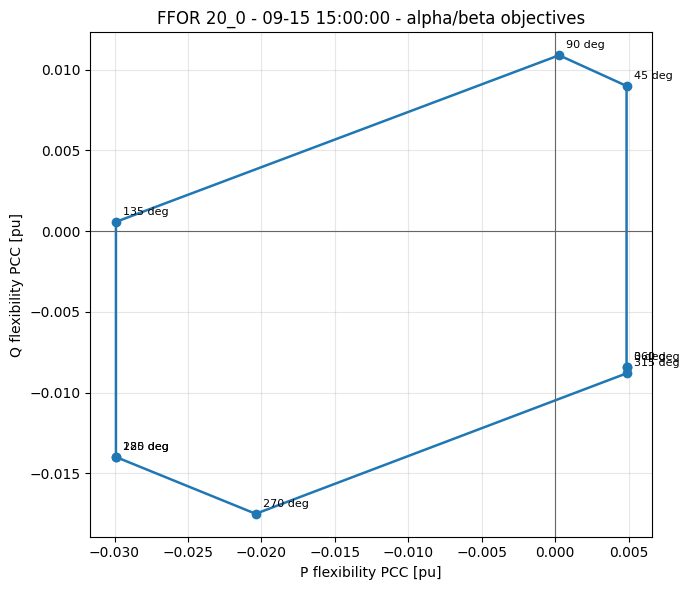

Saved outputs in: outputs\ffor_20_0_2030_09-15_15-00-00


In [13]:
closed_points = ffor_points[ffor_points["status"].eq("optimal")].copy()
if not closed_points.empty:
    first = closed_points.iloc[[0]].copy()
    first["angle_deg"] = 360
    closed_points = pd.concat([closed_points, first], ignore_index=True)

ffor_points.to_csv(OUTPUT_DIR / "ffor_boundary_points.csv", index=False)
closed_points.to_csv(OUTPUT_DIR / "ffor_boundary_closed.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(closed_points["P_flex_pu"], closed_points["Q_flex_pu"], marker="o", linewidth=1.8)
for _, row in closed_points.iterrows():
    ax.annotate(f"{int(row['angle_deg'])} deg", (row["P_flex_pu"], row["Q_flex_pu"]), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.axhline(0.0, color="0.4", linewidth=0.8)
ax.axvline(0.0, color="0.4", linewidth=0.8)
ax.set_xlabel("P flexibility PCC [pu]")
ax.set_ylabel("Q flexibility PCC [pu]")
ax.set_title(f"FFOR {GRID_NAME} - {TARGET_TIME} - alpha/beta objectives")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "ffor_polygon_delta_pq.png", dpi=160)
plt.show()

print(f"Saved outputs in: {OUTPUT_DIR}")


In [14]:
# Optional detail: line loading at each optimized boundary point.
line_flow_tables = []
for deg, x in solutions.items():
    flows = line_flow_values(x)
    flows.insert(0, "angle_deg", deg)
    line_flow_tables.append(flows)

if line_flow_tables:
    line_flows = pd.concat(line_flow_tables, ignore_index=True)
    line_flows.to_csv(OUTPUT_DIR / "line_flows_by_direction.csv", index=False)
    display(line_flows.sort_values("loading_ratio", ascending=False).head(10))


,angle_deg,from_bus,to_bus,direction,p_mw,q_mvar,s_mva,s_nom_mva,loading_ratio
434,180,9,45,from_to,-2.77259,-1.388487,3.100831,4.2,0.738293
534,225,9,45,from_to,-2.77259,-1.388487,3.100831,4.2,0.738293
435,180,45,9,to_from,2.77259,1.387446,3.100365,4.2,0.738182
535,225,45,9,to_from,2.77259,1.387446,3.100365,4.2,0.738182
575,225,104,43,to_from,-2.54208,-1.263963,2.838974,4.2,0.675946
475,180,104,43,to_from,-2.54208,-1.263963,2.838974,4.2,0.675946
574,225,43,104,from_to,2.54208,1.263562,2.838795,4.2,0.675904
474,180,43,104,from_to,2.54208,1.263562,2.838795,4.2,0.675904
334,135,9,45,from_to,-2.77259,-0.327091,2.791817,4.2,0.664718
335,135,45,9,to_from,2.77259,0.326049,2.791695,4.2,0.664689
